# Lab 5

We would like to work on identifying noise features in real quantum hardware. Given hardware, we're possibly interested in properties like how long the qubit will be coherent measured in T1 time (how long it'll continue to carry the information we need for computation), and error rate in readout. We know factors that material defects, temperature fluctuations, and recalibrations can impact the overall distribution dictated by the T1 time. So our idea involves fetching calibration data from IBM's devices and checking, based on accompanying metadata like per-qubit time series or daily chip heat maps, what kind of contamniation exists in the measured T1/readout error distribution of that chip.

We'll use June to October 2026 calibration data from IBM's Fez processor and check whether a "low" T1 time is normal for a given qubit or a temporary drop. A general timeline is the following:

1. Plot each qubit's T1 over time. Try to visually observe any outlier-like fluctuations and read the hardware spec to compare the plots against the ideal expected backgrounds.
2. For each day, we can look at the qubits in the chip's bottom 10-20% T1 times. And then we can single out the qubits that fluctuate, rather than qubits that are always low.
3. See what kind of physical reasons motivate this type of fluctuating behavior and try to model it. To test how correct our physical correction model is, we could try predicting the next day's T1 time conditioned on our priors. We can also test how "temporary" these fluctuations are by testing if the past 14 days or the past day's worth of data performs better at the prediction task.

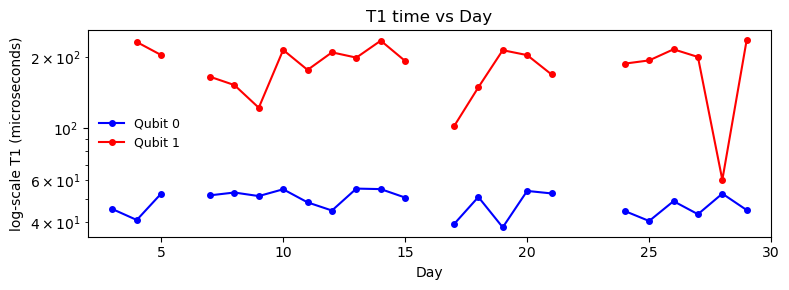

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, ScalarFormatter
import pandas as pd

# To get started, let's look at T1 times per qubit (on log scale) over the entirety of July
h5 = Path("fez_calibrations.h5")
data = pd.read_hdf(h5, key="calibrations",
                   where='property == "T1" & qubit_a in [0, 1] & is_new_measurement == True & unit == "us"')
data["date"] = pd.to_datetime(data["calibrated_time"], utc=True).dt.floor("D")
daily = data.pivot_table(index="date", columns="qubit_a", values="value", aggfunc="median")
july = daily.reindex(pd.date_range("2026-07-01", "2026-07-31", tz="UTC"))
july.index = july.index.day

colors = {0: "blue", 1: "red"}
fig, ax = plt.subplots(figsize=(8, 3))
for qubit, color in colors.items():
    ax.plot(july.index, july[qubit], marker="o", ms=4, color=color,
            label=f"Qubit {qubit}")

ax.set_yscale("log")
ax.set(xlim=(2, 30), xlabel="Day", ylabel="log-scale T1 (microseconds)",
       title="T1 time vs Day")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()